## 3D Mesh

I want to have a go at trying to plot a 3D mesh. I no longer have access to the current sun 3D data, but I have found the YS dome so I can test with that.

In [145]:
import cj_plotter
from music_scripts.musicdata import MusicData
import numpy as np
import matplotlib.pyplot as plt

In [146]:
# parameters used for the simulation (2d young sun)
r_env_init = 4.147678716913737E+10
r_tot = r_env_init / 0.44167
r_bot = 0.1 * r_tot
r_top = 0.97 * r_tot
Nr = 864
Ntheta = 270
# Nphi = 720
dr_grid = (r_top - r_bot) / Nr

In [147]:
import os

# Absolute path you want to convert
absolute_path = "/home/cj517/YS_dome_params/params_transient.nml" # PARAMS file defines cont series so remember to change this... (i.e. cont1 vs cont2...)
# Get relative path from current working directory
relative_path = os.path.relpath(absolute_path)
print(relative_path)

YS_dome_params/params_transient.nml


In [148]:
sim = MusicData(relative_path)

In [149]:
dump_idxs = []
for i in range(sim._len):
    try:
        sim[i]
        dump_idxs.append(i)
    except:
        continue
dump_idxs

[0, 100, 195, 320, 499]

In [158]:
spec_dump = -1

In [159]:
r = sim[dump_idxs[spec_dump]].grid.r_grid.cell_points()
theta = sim[dump_idxs[spec_dump]].grid.theta_grid.cell_points()
phi = sim[dump_idxs[spec_dump]].grid.phi_grid.cell_points()

In [160]:
vel_1 = sim[dump_idxs[spec_dump]].field['vel_1'].array()

In [161]:
from music_scripts.derived_fields import temp
T = temp(sim[dump_idxs[spec_dump]])
T_arr = T.array()
dT = T_arr - np.mean(T_arr, axis=1)[:, np.newaxis]

In [125]:
R3, T3, P3 = np.meshgrid(r, theta, phi, indexing='ij')   # each (nr, ntheta, nphi)

X = R3 * np.sin(T3) * np.cos(P3)
Y = R3 * np.sin(T3) * np.sin(P3)
Z = R3 * np.cos(T3)

PLOTTING OUTER
PLOTTING LEFT
DONE


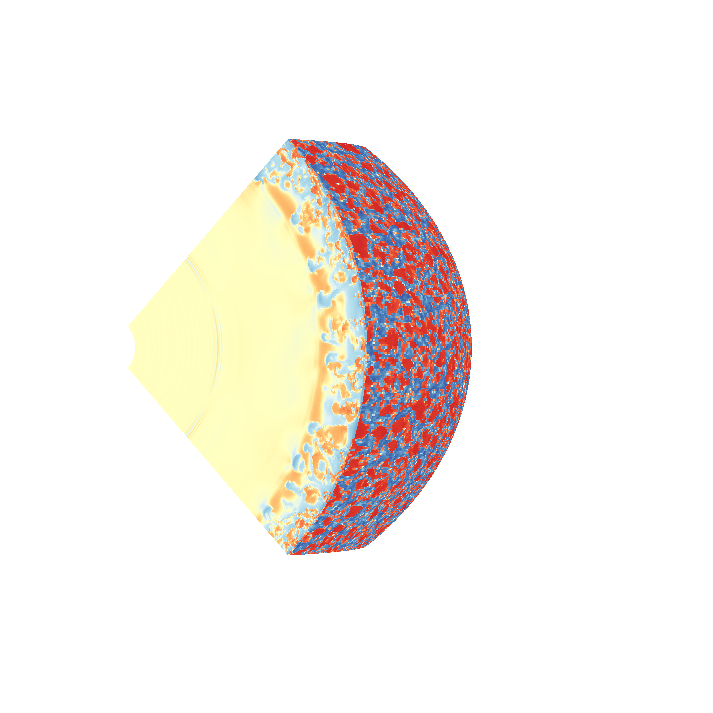

In [171]:
from matplotlib import cm
import matplotlib.colors as mplc
fig = plt.figure(figsize=(9, 9))
ax = fig.add_subplot(111, projection='3d')

vel_s = dT  # same strides as the coordinate meshgrid

vmin, vmax = -100,100
norm = norm = mplc.SymLogNorm(linthresh=0.1, vmin=vmin, vmax=vmax)
cmap = cm.RdYlBu

def draw_face(vf, Xf, Yf, Zf, stride=2):
    ax.plot_surface(Xf, Yf, Zf,
                    facecolors=cmap(norm(vf)),
                    rstride=stride, cstride=stride,
                    linewidth=0, antialiased=False, shade=False)

# outer & inner shells
print("PLOTTING OUTER")
draw_face(vel_s[-1], X[-1], Y[-1], Z[-1], stride=1)
# draw_face(vel_s[0],  X[0],  Y[0],  Z[0],stride=10)

# # bottom & top (theta)
# draw_face(vel_s[:, 0],  X[:, 0],  Y[:, 0],  Z[:, 0], stride=10)
# draw_face(vel_s[:, -1], X[:, -1], Y[:, -1], Z[:, -1],stride=5)
print("PLOTTING LEFT")
# # left & right (phi)
draw_face(vel_s[:, :, 0],  X[:, :, 0],  Y[:, :, 0],  Z[:, :, 0],stride=1)
# draw_face(vel_s[:, :, -1], X[:, :, -1], Y[:, :, -1], Z[:, :, -1], stride=10)
print("DONE")
m = cm.ScalarMappable(norm=norm, cmap=cmap)
# fig.colorbar(m, ax=ax, shrink=0.6, label='|v|')
ax.set_box_aspect([1, 1, 1])

ax.view_init(elev=0, azim=-45)
ax.set_axis_off()
fig.savefig("YS_dT_3D.png", bbox_inches="tight")